<table>
<tr><td><img style="height: 150px;" src="images/geo_hydro1.jpg"></td>
<td bgcolor="#FFFFFF">
    <p style="font-size: xx-large; font-weight: 900; line-height: 100%">pyRANDOM</p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);"><b style=color:red;>RANDOM</b> <b style=color:red;>NUMBERS</b></p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);">Georg Kaufmann</p>
    </td>
<td><img style="height: 150px;" src="images/pyRANDOM.png"></td>
</tr>
</table>

----
# `pyRANDOM`

pyRANDOM, a collection of jupyter notebooks playing with **random numbers** ...

----
# Traveling salesman problem: Solution for postal-code cities

In this notebook, we introduce the **traveling salesman** problem.



In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import libpyRANDOM

----
We come back to our introductory example, the 10 cities in Germany heading the postal codes.

- We first group the cities, along with their geographic coordinates, into a dictionary `citiesGermany`.
- We then extract the coordinates as `lon` and `lat` arrays, and the city names as `names` array.

In [2]:
citiesGermany = {
    'Leipzig': (12.387772, 51.343479),
    'Berlin': (13.404954, 52.520008), 
    'Hamburg': (9.993682, 53.551086),
    'Hannover': (9.73322, 52.37052),
    'Düsseldorf': (6.782048, 51.227144),
    'Köln': (6.953101, 50.935173),
    'Frankfurt am Main': (8.682127, 50.110924),
    'Stuttgart': (9.181332, 48.777128),
    'Munich': (11.576124, 48.137154),    
    'Nürnberg': (11.077438, 49.449820)
    
}

lons = np.array([]); lats = np.array([]); cities = np.array([],dtype='int'); names = []; 
i=0
for key,value in citiesGermany.items():
    lons = np.append(lons,[value[0]])
    lats = np.append(lats,[value[1]])
    cities = np.append(cities,[i])
    names.append(key)
    i += 1
for i in range(len(names)):
    print(cities[i],names[i],lons[i],lats[i])

0 Leipzig 12.387772 51.343479
1 Berlin 13.404954 52.520008
2 Hamburg 9.993682 53.551086
3 Hannover 9.73322 52.37052
4 Düsseldorf 6.782048 51.227144
5 Köln 6.953101 50.935173
6 Frankfurt am Main 8.682127 50.110924
7 Stuttgart 9.181332 48.777128
8 Munich 11.576124 48.137154
9 Nürnberg 11.077438 49.44982


We plot the cities with the `cartopy` package.

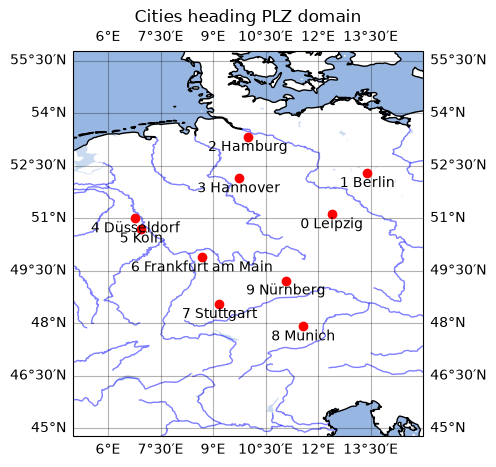

In [3]:
import warnings
warnings.filterwarnings('ignore')
fig = plt.figure(figsize=(10,5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([5, 15, 45, 56])
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False,color='black',alpha=0.3)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE,color='black')
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS,color='blue',alpha=0.5)
plt.title("Cities heading PLZ domain")
for i in range(len(names)):
    plt.plot(lons[i],lats[i],color='red', linewidth=2, marker='o',transform=ccrs.Geodetic())
    plt.text(lons[i],lats[i]-0.4, str(i)+' '+names[i],horizontalalignment='center',transform=ccrs.Geodetic())

----
## Shortest path based on ...

### Permutations

In [4]:
matrix = libpyRANDOM.tspCreateDistanceMatrix(lons,lats)
total_dist_min,total_dist_max,minorder = libpyRANDOM.tspPermutation(cities,matrix)

[0 1 2 3 4 5 6 7 8 9]
min path:  19.356665803421542
max path:  48.88212930125403
best path:  (0, np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), 0) 362880


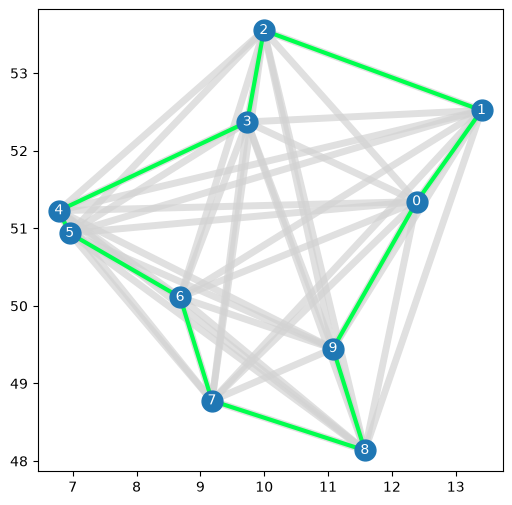

In [5]:
plt.figure(figsize=(6,6))

# plot all distances
for i in range(matrix.shape[0]):
        for j in range(i+1,matrix.shape[0]):
            if (np.isfinite(matrix[i][j])):
                plt.plot([lons[i],lons[j]],[lats[i],lats[j]],lw=5,alpha=0.7,color='lightgray')
# plot shortest distance
for i in range(1,len(minorder)):
            plt.plot([lons[minorder[i-1]],lons[minorder[i]]],[lats[minorder[i-1]],lats[minorder[i]]],lw=3,color=(0.0,1.0,0.3))
# plot nodes
plt.plot(lons,lats,lw=0,marker='o',markersize=15)
for i in range(len(lons)):
    plt.text(lons[i],lats[i],str(cities[i]),ha='center',va='center',color=(1,1,1))

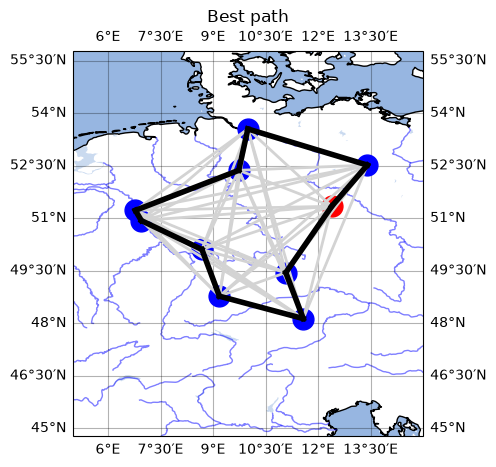

In [6]:
fig = plt.figure(figsize=(10,5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([5, 15, 45, 56])
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False,color='black',alpha=0.3)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.COASTLINE,color='black')
ax.add_feature(cfeature.LAKES, alpha=0.5)
ax.add_feature(cfeature.RIVERS,color='blue',alpha=0.5)
plt.title("Best path")
plt.plot(lons[0],lats[0],lw=0,marker='o',color='red',markersize=15)
plt.plot(lons[1:],lats[1:],lw=0,marker='o',color='blue',markersize=15)
for i in range(matrix.shape[0]):
        for j in range(i+1,matrix.shape[0]):
            if (np.isfinite(matrix[i][j])):
                plt.plot([lons[i],lons[j]],[lats[i],lats[j]],lw=2,color='lightgray')
for i in range(1,len(minorder)):
            plt.plot([lons[minorder[i-1]],lons[minorder[i]]],
                     [lats[minorder[i-1]],lats[minorder[i]]],lw=4,color='black')

----